# Satellite thermal imagery as a data feed for an urban heat island digital twin
**Tunis · DTT4SD workshop, 10 November 2026 · Session 4, hands-on**

Author: Bruno Ćaleta · Oikon Ltd.

Contact: bcaleta@oikon.hr

You will build the first two levels of a digital twin with real satellite data and Google Earth Engine.

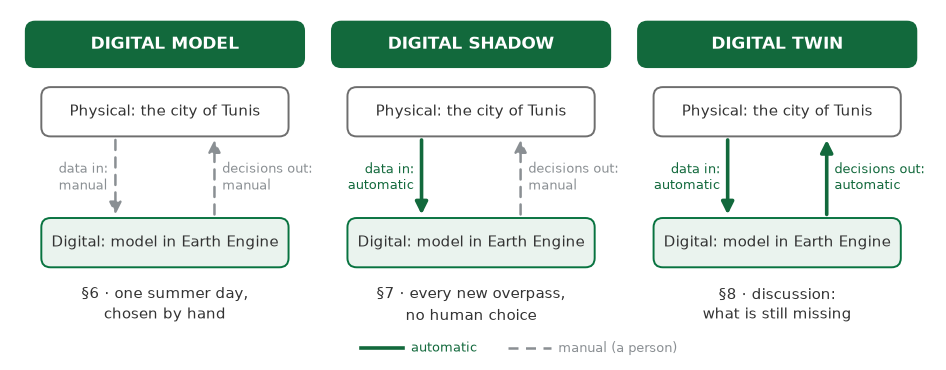

<sub>Three levels of integration (Kritzinger et al. 2018).</sub>

**Plan**

| § | What you do | Estimated Minutes |
|---|---|---|
| 1–2 | Connect to Earth Engine and define the study area | 10 |
| 3 | Find the clear summer days and look at one Landsat scene | 5 |
| 4 | Turn the thermal band into land surface temperature | 6 |
| 5 | Describe the land cover with Dynamic World | 5 |
| 6 | Stage 1 · Digital model: train and test | 9 |
| 7 | Stage 2 · Digital shadow: a live feed of the newest overpass | 8 |
| 8 | Stage 3 · Digital twin: simulate planting trees, close the loop | 10 |
| 9 | Use it for your own area | after the workshop |

**How to use it**
- First save your own copy: **File → Save a copy in Drive**.
- The copy opens in a new tab, named "Copy of …". Work in that tab and close this one. You find the copy later in Google Drive, folder **Colab Notebooks**.
- Run the cells in order with **Shift + Enter**.
- ✏️ means a value you may change.
- 🔍 means a check that the step worked.
- Fallen behind? Click the first cell of the current section and choose **Runtime → Run before**.

**You need** a Google account. We create your Earth Engine project together at the start of the session, in section 1.

## 1 · Connect to Google Earth Engine
Google Earth Engine (GEE) is a catalogue of satellite and climate data plus Google's computers that process the data where it is stored. Your notebook only sends instructions and receives small results: numbers, tables and map tiles. Every instruction runs on the quota of your Cloud project.

**Create your Cloud project (once, about 5 minutes, free)**
1. **Create the project.** Open [console.cloud.google.com/projectcreate](https://console.cloud.google.com/projectcreate). On your first visit, accept the terms of service. Type a project name, for example `tunis-uhi`. Under the name, Google shows the **project ID**. Write it down. Click **Create**. You do not need a billing account.
2. **Register it for Earth Engine.** Open the [Earth Engine page of the Cloud console](https://console.cloud.google.com/earth-engine/configuration). At the top of the page, select your new project. Click **Register**. Choose **noncommercial** use. As organisation type, choose **Earth Engine trainer or trainee**. If the form asks about the training, write "DTT4SD workshop, Tunis, 10 November 2026". Keep the free **Community** tier. If the page offers to enable the Earth Engine API, click **Enable**.
3. **Connect.** Type the project ID in cell 1.1. Run cells 1.1 and 1.2. If 1.2 reports an error about registration or the API, repeat step 2 for this project.
4. **Let's explore Google Earth Engine** for a bit. Open the [Data Catalog](https://developers.google.com/earth-engine/datasets/catalog).

In [1]:
#@title 1.1 · Your Google Cloud project ✏️
PROJECT_ID = "your-project-id"  #@param {type:"string"}
# ✏️ Type the ID of the Cloud project you registered for Earth Engine (the ID, not the display name).

In [2]:
#@title 1.2 · Connect to Earth Engine 🔍
import os
import ee

ee.Authenticate()                         # Colab asks you to allow access with your Google account
ee.Initialize(project=PROJECT_ID)         # every request now runs, for free, on your project's quota
os.environ["EE_PROJECT_ID"] = PROJECT_ID  # geemap, our map library, uses the same project

n_scenes = (ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
            .filterBounds(ee.Geometry.Point([10.18, 36.80]))
            .size()
            .getInfo())  # .getInfo() = "run this on Google's computers and bring the answer back"
print(f"Connected to Earth Engine with project '{PROJECT_ID}'.")
print(f"Landsat 9 scenes over Tunis in the catalogue: {n_scenes}")

Connected to Earth Engine with project 'your-project-id'.
Landsat 9 scenes over Tunis in the catalogue: 216


In [3]:
#@title 1.3 · Toolbox: helpers for maps and tables (run it, no need to read it) { display-mode: "form" }
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:  # interactive map widgets in Colab
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

import geemap

CENTER = [36.83, 10.18]  # map centre: latitude, longitude
DW_CLASSES = ["water", "trees", "grass", "flooded_vegetation", "crops",
              "shrub_and_scrub", "built", "bare", "snow_and_ice"]
DW_NAMES = ["Water", "Trees", "Grass", "Flooded vegetation", "Crops",
            "Shrub & scrub", "Built", "Bare", "Snow & ice"]
DW_COLORS = ["419bdf", "397d49", "88b053", "7a87c6", "e49635",
             "dfc35a", "c4281b", "a59b8f", "b39fe1"]
HEAT = ["313695", "4575b4", "74add1", "abd9e9", "e0f3f8", "ffffbf",
        "fee090", "fdae61", "f46d43", "d73027", "a50026"]
DIVERGING = ["2166ac", "4393c3", "92c5de", "d1e5f0", "f7f7f7",
             "fddbc7", "f4a582", "d6604d", "b2182b"]

bands = pd.DataFrame([
    ("SR_B1", "Coastal / aerosol", "0.43–0.45 µm", "surface reflectance"),
    ("SR_B2", "Blue", "0.45–0.51 µm", "true-colour image"),
    ("SR_B3", "Green", "0.53–0.59 µm", "true-colour image"),
    ("SR_B4", "Red", "0.64–0.67 µm", "true colour; plants absorb red"),
    ("SR_B5", "Near infrared", "0.85–0.88 µm", "healthy plants reflect strongly"),
    ("SR_B6", "Shortwave infrared 1", "1.57–1.65 µm", "moisture in soil and leaves"),
    ("SR_B7", "Shortwave infrared 2", "2.11–2.29 µm", "moisture, minerals"),
    ("ST_B10", "Thermal infrared", "10.6–11.2 µm", "★ land surface temperature"),
    ("QA_PIXEL", "Quality flags", "–", "★ cloud and cloud-shadow mask"),
    ("ST_ATRAN, ST_EMIS, …", "Inputs of the temperature retrieval", "–", "atmosphere and emissivity used by USGS"),
], columns=["band", "what it records", "wavelength", "used for"])

def new_map(zoom=11, center=None):
    """An interactive map, centred on Tunis unless told otherwise."""
    return geemap.Map(center=center or CENTER, zoom=zoom, basemap="SATELLITE") # or ROADMAP

def outline(geometry, color="000000", width=2):
    """The outline of a geometry as a map layer, without fill."""
    fc = ee.FeatureCollection([ee.Feature(geometry)])
    return ee.Image().byte().paint(fc, 1, width).visualize(palette=[color])

def add_colorbar(m, vis, label):
    try:
        m.add_colorbar(vis, label=label)
    except Exception:
        pass  # a colour bar is nice to have, not essential

def add_legend(m, title, names, colors):
    legend = {n: "#" + c for n, c in zip(names, colors)}
    try:
        m.add_legend(title=title, legend_dict=legend)
    except Exception:
        try:
            m.add_legend(legend_title=title, legend_dict=legend)
        except Exception:
            pass

def fc_to_df(fc):
    """Print FeatureCollection attributes as Data Frame."""
    return pd.DataFrame([f["properties"] for f in fc.getInfo()["features"]])

def scores(df, obs="LST", pred="LST_pred"):
    """R², RMSE and MAE of predicted vs observed values."""
    err = df[pred] - df[obs]
    r2 = 1 - (err ** 2).sum() / ((df[obs] - df[obs].mean()) ** 2).sum()
    return {"R²": round(float(r2), 2),
            "RMSE (°C)": round(float(np.sqrt((err ** 2).mean())), 2),
            "MAE (°C)": round(float(err.abs().mean()), 2),
            "test pixels": len(df)}

print("✅ Toolbox ready.")

✅ Toolbox ready.


## 2 · Study area and the data catalogue
We use three datasets:

| Dataset | Catalogue ID | What we take from it |
|---|---|---|
| [Landsat 8, Level 2](https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC08_C02_T1_L2) | `LANDSAT/LC08/C02/T1_L2` | surface temperature, cloud mask |
| [Landsat 9, Level 2](https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC09_C02_T1_L2) | `LANDSAT/LC09/C02/T1_L2` | the same from the second satellite |
| [Dynamic World V1](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_DYNAMICWORLD_V1) | `GOOGLE/DYNAMICWORLD/V1` | 9 land-cover classes |

In [4]:
#@title 2.1 · Where and when ✏️
AOI = ee.Geometry.Rectangle([10.00, 36.65, 10.35, 36.95])  # ✏️ [west, south, east, north] in degrees: Tunis
MODEL_START, MODEL_END = "2025-06-01", "2025-09-01"    # ✏️ digital model: summer 2025, June to August (the end date is not included)
SCALE = 90          # metres: Landsat's thermal sensor sees ~100 m, so we work on a 90 m grid
CRS = "EPSG:32632"  # UTM zone 32N, the map projection Landsat uses over Tunisia

print(f"🔍 Study area: {AOI.area(maxError=1).divide(1e6).getInfo():.0f} km²")
m = new_map(zoom=10)
m.addLayer(outline(AOI), {}, "Study area")
display(m)

🔍 Study area: 1040 km²


Map(center=[36.83, 10.18], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

In [5]:
#@title 2.2 · Get to know the data in your area? 🔍
# Two compatible collections
L8 = "LANDSAT/LC08/C02/T1_L2"
L9 = "LANDSAT/LC09/C02/T1_L2"

# Merge collections and fetch ALL existing images
landsat = ee.ImageCollection(L8).merge(ee.ImageCollection(L9)).filterBounds(AOI)

print(f"Landsat 8 and 9 Level-2 scenes falling over the study area: {landsat.size().getInfo()}")
print(f"First: {ee.Date(landsat.aggregate_min("system:time_start")).format("YYYY-MM-dd").getInfo()}")
print(f"Latest: {ee.Date(landsat.aggregate_max("system:time_start")).format("YYYY-MM-dd").getInfo()}")

Landsat 8 and 9 Level-2 scenes falling over the study area: 1600


First: 2013-03-29


Latest: 2026-10-27


## 3 · Observe one Landsat scene
> **Learning objectives**
> - Find all clear Landsat overpasses of one summer.
> - Choose one date for training the digital model.
> - Get to know the bands of a Landsat Level-2 scene.

- Landsat 8 and 9 cross Tunis at about 11:00 local time.
- Each overpass is delivered as tiles of about 185 × 180 km.
- Not each tile covers the whole AOI.
- So if we have multiple tiles of the same day we merge them into one image called a *daily mosaic*.
- Then we measure how much of the study area is free of clouds on each day.

In [6]:
#@title 3.1 · Which summer days were clear over Tunis? 🔍
def fetch_landsat_collection(start, end):
    """Landsat 8 and 9 Level-2 scenes over the study area that are not mostly cloud."""
    return (ee.ImageCollection(L8).merge(ee.ImageCollection(L9))
            .filterBounds(AOI)
            .filterDate(start, end) # Summer 2025
            .filter(ee.Filter.lt("CLOUD_COVER", 60)))

def daily_mosaics(collection):
    """Merges multiple tiles if taken on the same day."""
    collection = collection.map(
        lambda img: img.set("day", ee.Date(img.get("system:time_start")).format("YYYY-MM-dd")))
    days = ee.List(collection.aggregate_array("day")).distinct().sort()

    def one_day(day):
        tiles = collection.filter(ee.Filter.eq("day", day))
        return (tiles.mosaic()
                .set("day", day)
                .set("system:time_start", ee.Date(day).millis())
                .set("satellite", tiles.first().get("SPACECRAFT_ID")))

    return ee.ImageCollection.fromImages(days.map(one_day))

def mask_clouds(img):
    """
    Identifies pixels that have QA_PIXEL flags for clouds:
    dilated cloud (bit 1), cirrus (2), cloud (3) or cloud shadow (4).
    """
    flagged = img.select("QA_PIXEL").bitwiseAnd(0b11110).neq(0)
    return img.updateMask(flagged.Not())


def to_lst(img):
    """
    Masks clouds on one scene, selects only the thermal banc
    and calculates land surface temperature in °C.
    """
    lst = (mask_clouds(img).select("ST_B10")
           .multiply(0.00341802).add(149.0)   # → kelvin (USGS scale factor and offset)
           .subtract(273.15)                   # → degrees Celsius
           .rename("LST"))
    return ee.Image(lst.copyProperties(img, ["day", "satellite", "system:time_start"]))


def clear_share(img):
    """
    Calculates the share of the study area where the ground
    is not covered with clouds on the scene level (0–1).
    """
    visible = to_lst(img).gt(-100).unmask(0, False)   # 1 = visible, 0 = cloud or outside the tiles
    share = visible.reduceRegion(ee.Reducer.mean(), AOI, 300, maxPixels=1e9).get("LST")
    return ee.Feature(None, {"day": img.get("day"), "satellite": img.get("satellite"),
                             "clear_share": share})

l2_collection = fetch_landsat_collection(MODEL_START, MODEL_END)
days_model = daily_mosaics(l2_collection)

clear_m = fc_to_df(ee.FeatureCollection(days_model.map(clear_share)))
clear_m["clear_share"] = (100 * clear_m["clear_share"]).round(1)

print(f"🔍 Summer 2025 had {len(clear_m)} overpasses.")
display(clear_m[["day", "satellite", "clear_share"]].rename(columns={"day": "date", "clear_share": "clear share of study area (%)"}))

🔍 Summer 2025 had 24 overpasses.


,date,satellite,clear share of study area (%)
0,2025-06-01,LANDSAT_8,29.2
1,2025-06-02,LANDSAT_9,99.4
2,2025-06-09,LANDSAT_9,30.0
3,2025-06-10,LANDSAT_8,99.8
4,2025-06-17,LANDSAT_8,23.8
5,2025-06-18,LANDSAT_9,35.0
6,2025-06-25,LANDSAT_9,25.6
7,2025-06-26,LANDSAT_8,100.0
8,2025-07-03,LANDSAT_8,10.9
9,2025-07-04,LANDSAT_9,97.8


In [7]:
#@title 3.2 · Choose the date of the digital model ✏️
SCENE_DATE = "2025-07-20"  #@param {type:"string"}
# ✏️ The clearest day of summer 2025. Any date from the table above works.

assert SCENE_DATE in clear_m["day"].values, f"No overpass on {SCENE_DATE}. Pick a date from the table of 3.1."

scene = ee.Image(days_model.filter(ee.Filter.eq("day", SCENE_DATE)).first())
print(f"📅 Digital model date: {SCENE_DATE} ({scene.get('satellite').getInfo()})")

📅 Digital model date: 2025-07-20 (LANDSAT_9)


In [8]:
#@title 3.3 · What is inside a Landsat scene? 🔍
display(bands)

optical = (scene.select(["SR_B4", "SR_B3", "SR_B2", "SR_B5"])
           .multiply(0.0000275).add(-0.2))

m = new_map()
m.addLayer(optical.clip(AOI), {"bands": ["SR_B4", "SR_B3", "SR_B2"], "min": 0, "max": 0.3},
           "True colour (red, green, blue)")
m.addLayer(scene.select("ST_B10").clip(AOI), {"min": 42000, "max": 53000},
           "Thermal band, raw numbers (bright = hot)", False)
m.addLayer(outline(AOI), {}, "Study area")
display(m)
print("🔍 Use the layer button (top right of the map) to toggle layers.")

,band,what it records,wavelength,used for
0,SR_B1,Coastal / aerosol,0.43–0.45 µm,surface reflectance
1,SR_B2,Blue,0.45–0.51 µm,true-colour image
2,SR_B3,Green,0.53–0.59 µm,true-colour image
3,SR_B4,Red,0.64–0.67 µm,true colour; plants absorb red
4,SR_B5,Near infrared,0.85–0.88 µm,healthy plants reflect strongly
5,SR_B6,Shortwave infrared 1,1.57–1.65 µm,moisture in soil and leaves
6,SR_B7,Shortwave infrared 2,2.11–2.29 µm,"moisture, minerals"
7,ST_B10,Thermal infrared,10.6–11.2 µm,★ land surface temperature
8,QA_PIXEL,Quality flags,–,★ cloud and cloud-shadow mask
9,"ST_ATRAN, ST_EMIS, …",Inputs of the temperature retrieval,–,atmosphere and emissivity used by USGS


Map(center=[36.83, 10.18], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

🔍 Use the layer button (top right of the map) to toggle layers.


## 4 · From the thermal band to land surface temperature
> **Learning objectives**
> - Understanding surface temeperature and DN.
> - Convert the thermal band from raw numbers to °C.
> - Read a land surface temperature map.

Every surface sends out heat radiation, and hotter surfaces send out more. Landsat's thermal band (band 10, 10.6–11.2 µm) records this radiation as raw numbers called *digital numbers* (DN). We  convert DN numbers into physical units with their scaling factors:

$$\text{LST [K]} = \text{DN} \times 0.00341802 + 149.0 \qquad \text{LST [°C]} = \text{LST [K]} - 273.15$$

> ⚠️ Land surface temperature (LST) is the temperature of roofs, roads, soil and leaves, not of the air. At 11:00 in summer the surface is often more than 10 °C hotter than the air.

In [9]:
#@title 4.1 · Do the conversion by hand for four quality checks 🔍
QC_POINTS = ee.FeatureCollection([  # ✏️ approximate locations; 5.1 checks what land cover they fall on
    ee.Feature(ee.Geometry.Point([10.1682, 36.7979]), {"place": "Medina of Tunis (dense old town)"}),
    ee.Feature(ee.Geometry.Point([10.2300, 36.8200]), {"place": "Lake of Tunis (water)"}),
])

thermal_band = scene.select("ST_B10")

# Sample the thermal band with our QC points
raw = fc_to_df(thermal_band.sampleRegions(collection=QC_POINTS, scale=30))

# Apllying scaling factors for DN -> K conversion
raw["kelvin"] = raw["ST_B10"] * 0.00341802 + 149.0 # scaling factors

# K -> °C conversion
raw["°C"] = raw["kelvin"] - 273.15

display(raw[["place", "ST_B10", "kelvin", "°C"]].rename(columns={"ST_B10": "raw number (DN)"}).round(1))

,place,raw number (DN),kelvin,°C
0,Medina of Tunis (dense old town),49716,318.9,45.8
1,Lake of Tunis (water),45580,304.8,31.6


🔍 LST on 2025-07-20: 2nd percentile 27.9 °C · median 48.4 °C · 98th percentile 56.4 °C


Map(center=[36.83, 10.18], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

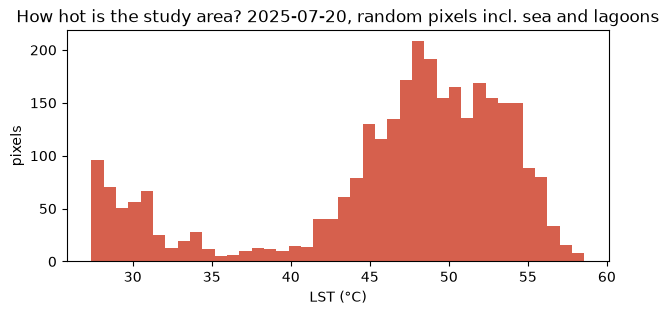

In [10]:
#@title 4.2 · The whole map, clouds removed 🔍
lst = to_lst(scene) # Don't calculate LST by hand, use the to_lst function

lst_percentiles = lst.reduceRegion(ee.Reducer.percentile([2, 50, 98]), AOI, SCALE, crs=CRS, maxPixels=1e9).getInfo()
LST_VIS = {"min": round(lst_percentiles["LST_p2"]), "max": round(lst_percentiles["LST_p98"]), "palette": HEAT}
print(f"🔍 LST on {SCENE_DATE}: 2nd percentile {lst_percentiles['LST_p2']:.1f} °C · median {lst_percentiles['LST_p50']:.1f} °C · "
      f"98th percentile {lst_percentiles['LST_p98']:.1f} °C")

m = new_map()
m.addLayer(lst.clip(AOI), LST_VIS, f"Land surface temperature {SCENE_DATE} (°C)")
m.addLayer(outline(AOI), {}, "Study area")
add_colorbar(m, LST_VIS, "LST (°C)")
display(m)

pixels = fc_to_df(lst.sample(region=AOI, scale=SCALE, projection=ee.Projection(CRS), numPixels=3000, seed=1))
ax = pixels["LST"].plot.hist(bins=40, color="#d6604d", figsize=(7, 3))
ax.set_xlabel("LST (°C)")
ax.set_ylabel("pixels")
ax.set_title(f"How hot is the study area? {SCENE_DATE}, random pixels incl. sea and lagoons")
plt.show()

### ✅ Recap
- One clear overpass gives the surface temperature of the whole study area in °C.
- The cloud mask hides pixels that would look falsely cool.
- The sea and the lagoons are the coolest surfaces. On land, the temperature differs by more than 10 °C between places.

Next: what is the ground made of, and does it explain these differences?

## 5 · Dynamic World and Land Use/Land Cover
> **Learning objectives**
> - Describe land cover as class probabilities, not as one label.
> - Quality check that known places get the right class.
> - Build the training set that feeds the model.

Dynamic World classifies every Sentinel-2 image at 10 m into 9 classes. Instead of one label, it gives each pixel a probability for every class, e.g. 0.6 built, 0.3 trees, 0.1 grass. Averaged over a summer, these probabilities behave like the share of each cover inside the pixel. That makes them good inputs for a model of temperature, which also mixes everything inside a 100 m thermal pixel.

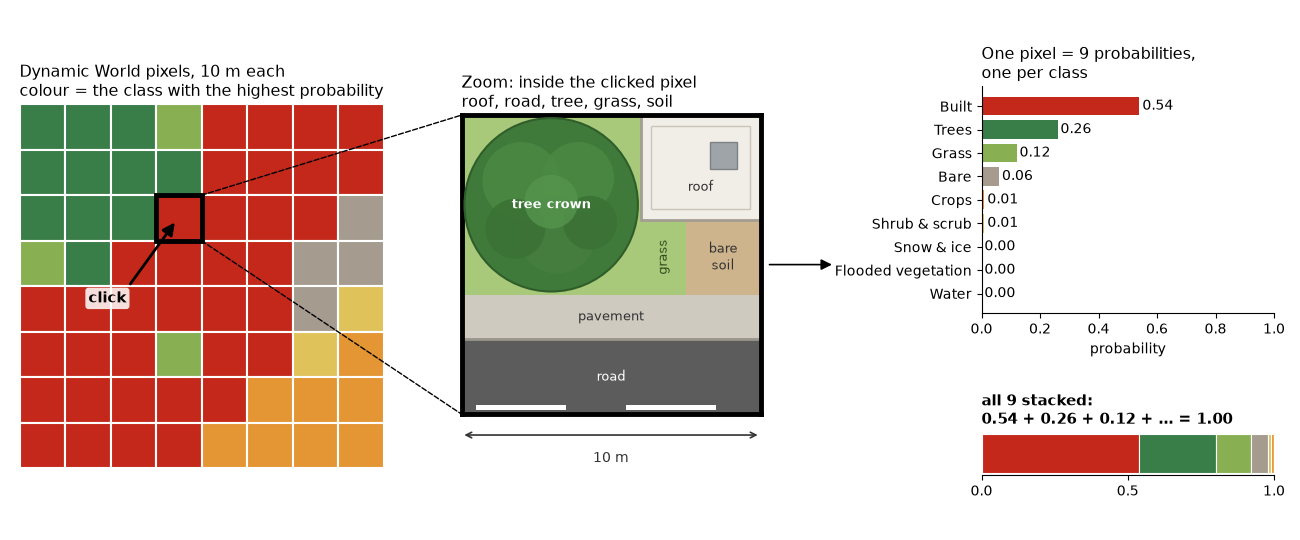

Map(center=[36.83, 10.18], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

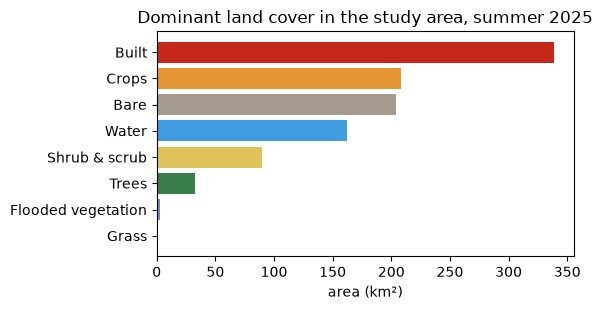

🔍 Do the four places fall on the land cover their names promise?


,place,Dynamic World says
0,Medina of Tunis (dense old town),Built
1,Lake of Tunis (water),Water


In [11]:
#@title 5.1 · Dynamic World: land cover of the same summer 🔍
def dynamic_world(start, end):
    """Mean probability (0–1) of each Dynamic World class between two dates."""
    return (ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
            .filterBounds(AOI)
            .filterDate(start, end)
            .select(DW_CLASSES)
            .mean())


def dominant(dw):
    """Number (0–8) of the class with the highest probability."""
    return dw.toArray().arrayArgmax().arrayGet([0]).rename("label")


dw_model = dynamic_world(MODEL_START, MODEL_END)
label = dominant(dw_model)
land = dw_model.select("water").lt(0.5)   # we model land only: sea and lagoons are left out

m = new_map()
m.addLayer(label.clip(AOI), {"min": 0, "max": 8, "palette": DW_COLORS}, "Dominant class, summer 2025")
m.addLayer(dw_model.select("trees").clip(AOI), {"min": 0, "max": 1, "palette": ["ffffff", "397d49"]},
           "Probability of trees", False)
m.addLayer(dw_model.select("built").clip(AOI), {"min": 0, "max": 1, "palette": ["ffffff", "c4281b"]},
           "Probability of built-up", False)
m.addLayer(QC_POINTS.style(color="000000", pointSize=5), {}, "The four places from 4.1")
add_legend(m, "Dynamic World", DW_NAMES, DW_COLORS)
display(m)

groups = (ee.Image.pixelArea().divide(1e6).addBands(label)
          .reduceRegion(ee.Reducer.sum().group(groupField=1, groupName="class"),
                        AOI, SCALE, crs=CRS, maxPixels=1e9)
          .get("groups").getInfo())
shares = pd.DataFrame(groups).sort_values("sum")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh([DW_NAMES[int(c)] for c in shares["class"]], shares["sum"],
        color=["#" + DW_COLORS[int(c)] for c in shares["class"]])
ax.set_xlabel("area (km²)")
ax.set_title("Dominant land cover in the study area, summer 2025")
plt.tight_layout()
plt.show()

check = fc_to_df(label.sampleRegions(collection=QC_POINTS, scale=SCALE))
check["Dynamic World says"] = [DW_NAMES[int(c)] for c in check["label"]]
print("🔍 Do the four places fall on the land cover their names promise?")
display(check[["place", "Dynamic World says"]])

In [12]:
#@title 5.2 · 4000 random land pixels: a first look at heat and land cover 🔍
def build_training_set(lst_img, dw, n=4000, seed=42):
    """Read every layer at n random land pixels: the raw material of the model."""
    stack = (dw.select(DW_CLASSES)
             .addBands(dominant(dw)) # for sampling DW probabilities
             .addBands(lst_img.select("LST")) # for sampling LST
             .updateMask(dw.select("water").lt(0.5)))
    return stack.sample(region=AOI, scale=SCALE, projection=ee.Projection(CRS),
                        numPixels=n, seed=seed, geometries=True, tileScale=4)

samples = build_training_set(lst, dw_model)
training_set = fc_to_df(samples)
print(f"🔍 {len(training_set)} land pixels, each with {training_set.shape[1]} values (LST, 9 probabilities, dominant class)")

🔍 3429 land pixels, each with 11 values (LST, 9 probabilities, dominant class)


In [13]:
training_set

,LST,bare,built,crops,flooded_vegetation,grass,label,shrub_and_scrub,snow_and_ice,trees,water
0,55.022608,0.359643,0.047932,0.300177,0.028149,0.037231,7,0.115550,0.042519,0.027441,0.037247
1,48.945369,0.118095,0.585260,0.053342,0.033927,0.034033,6,0.057109,0.051415,0.027201,0.036746
2,52.271102,0.174855,0.495382,0.054324,0.031664,0.032932,6,0.084796,0.060614,0.025522,0.034395
3,49.919505,0.207848,0.044727,0.293514,0.038793,0.039986,4,0.167511,0.045860,0.091278,0.041904
4,54.711569,0.306381,0.041626,0.152430,0.029708,0.036798,5,0.307389,0.047198,0.042796,0.026384
...,...,...,...,...,...,...,...,...,...,...,...
3424,52.817986,0.084304,0.237550,0.344138,0.030593,0.070920,4,0.098933,0.045280,0.030664,0.030786
3425,51.754981,0.211524,0.038828,0.437019,0.033701,0.060995,4,0.093884,0.040925,0.031545,0.046926
3426,43.544897,0.064989,0.674780,0.037949,0.031914,0.037701,6,0.040377,0.050345,0.032761,0.026116
3427,49.622137,0.086728,0.049253,0.519192,0.027931,0.062935,4,0.113873,0.046752,0.053735,0.030327


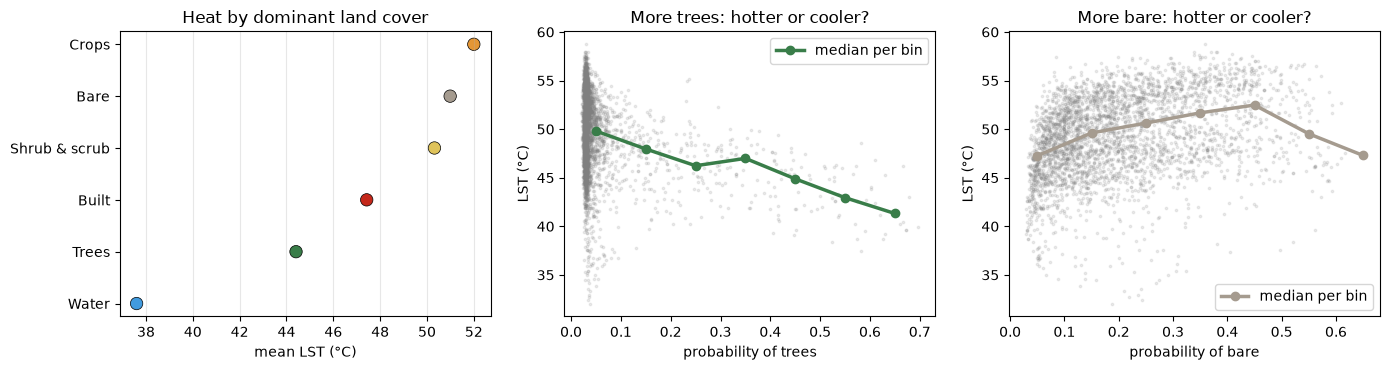

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
by_class = training_set.groupby("label")["LST"].agg(["mean", "count"]).reset_index()
by_class = by_class[by_class["count"] >= 20].sort_values("mean")
axes[0].scatter(by_class["mean"], [DW_NAMES[int(c)] for c in by_class["label"]], s=80,
                color=["#" + DW_COLORS[int(c)] for c in by_class["label"]], edgecolor="black", linewidth=0.5)
axes[0].grid(axis="x", alpha=0.3)
axes[0].set_xlabel("mean LST (°C)")
axes[0].set_title("Heat by dominant land cover")
for ax, cls, color in [(axes[1], "trees", "#397d49"), (axes[2], "bare", "#a59b8f")]:
    bins = pd.cut(training_set[cls], np.linspace(0, 1, 11), include_lowest=True)
    med = training_set.groupby(bins, observed=True)["LST"].median()
    ax.scatter(training_set[cls], training_set["LST"], s=3, alpha=0.15, color="grey")
    ax.plot([b.mid for b in med.index], med.values, color=color, lw=2.5, marker="o", label="median per bin")
    ax.set_xlabel(f"probability of {cls}")
    ax.set_ylabel("LST (°C)")
    ax.set_title(f"More {cls}: hotter or cooler?")
    ax.legend()
plt.tight_layout()
plt.show()

### ✅ Recap
- Dynamic World describes every pixel with 9 probabilities.
- We use those probabilities as predictors for estimating LST.

Next: let a model learn the link between land cover and heat.

## 6 · Stage 1 · Digital model: how much of the heat does land cover explain?
> **Learning objectives**
> - Train a Random Forest that explains LST from land cover.
> - Test it on pixels it has never seen.

A *Random Forest* is a set of many decision trees. Each tree learns simple rules from examples, such as "few trees and much built-up land → hot". The forest averages the answers of all its trees. In GEE it runs on Google's servers (`ee.Classifier.smileRandomForest`) in *regression* mode, because we predict a number (°C), not a class.

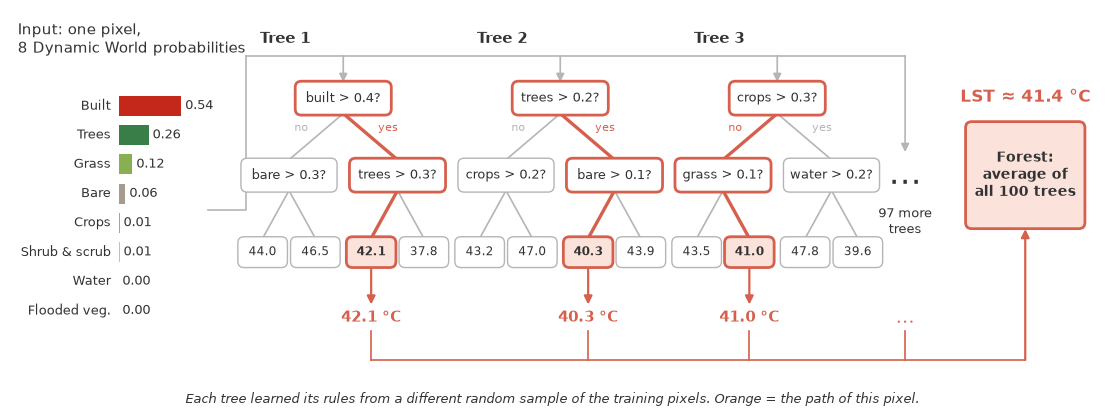

**Training and test.** We hide 30 % of the pixels from the model. It learns from the other 70 %. Then we compare its predictions with the observed temperature of the hidden pixels. A model is never tested on pixels it has learned from.

In [15]:
#@title 6.1 · Split the pixels into a training set and a test set 🔍
TEST_SHARE = 0.3   # 30 % of the pixels are kept for testing only

pixels = samples.randomColumn("random", seed=42)              # every pixel gets a random number between 0 and 1
train = pixels.filter(ee.Filter.gte("random", TEST_SHARE))   # about 70 %: the model learns from these
test = pixels.filter(ee.Filter.lt("random", TEST_SHARE))     # about 30 %: the model never sees these

n_train, n_test = ee.List([train.size(), test.size()]).getInfo()
print(f"🔍 {n_train} pixels for training, {n_test} for testing")

🔍 2408 pixels for training, 1021 for testing


In [16]:
m = new_map()
m.addLayer(train.style(color="2166ac", pointSize=2), {}, "Training pixels (blue)")
m.addLayer(test.style(color="d6604d", pointSize=2), {}, "Test pixels (red)")
display(m)

Map(center=[36.83, 10.18], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

In [17]:
#@title 6.2 · Train the Random Forest 🔍
FEATURES = [c for c in DW_CLASSES if c != "snow_and_ice"]   # inputs: 8 Dynamic World probabilities
# Snow & ice is left out. There is no snow in Tunis in summer; the forest would use it as a sign of bright surfaces.
rf = (ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42)
      .setOutputMode("REGRESSION")
      .train(features=train, classProperty="LST", inputProperties=FEATURES))

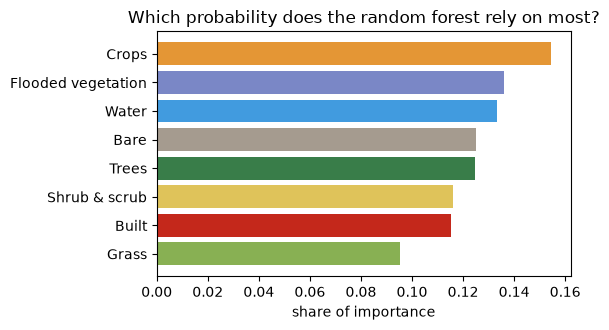

In [18]:
# importance = how much each input improves the forest's predictions (shown as shares that add up to 1)
importance = pd.Series(rf.explain().get("importance").getInfo()).reindex(FEATURES).fillna(0)
importance = (importance / importance.sum()).sort_values()
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.barh([DW_NAMES[DW_CLASSES.index(c)] for c in importance.index], importance.values,
        color=["#" + DW_COLORS[DW_CLASSES.index(c)] for c in importance.index])
ax.set_xlabel("share of importance")
ax.set_title("Which probability does the random forest rely on most?")
plt.tight_layout()
plt.show()

🔍 Test pixels: R² = 0.77 · RMSE = 1.97 °C · MAE = 1.51 °C · 1021 pixels


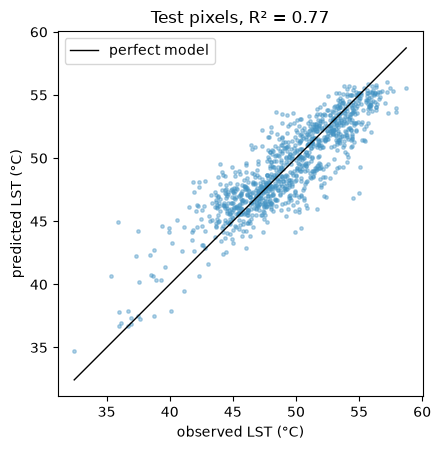

In [19]:
#@title 6.3 · How good is the model on pixels it has never seen? 🔍
# R² = share of the temperature differences between pixels that the model explains (1 = all of them).
# RMSE and MAE = the typical size of an error in °C.
pred_test = fc_to_df(test.classify(rf, "LST_pred").select(["LST", "LST_pred"]))
s = scores(pred_test)
print(f"🔍 Test pixels: R² = {s['R²']} · RMSE = {s['RMSE (°C)']} °C · MAE = {s['MAE (°C)']} °C · "
      f"{s['test pixels']} pixels")

lo = pred_test[["LST", "LST_pred"]].min().min()
hi = pred_test[["LST", "LST_pred"]].max().max()
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.scatter(pred_test["LST"], pred_test["LST_pred"], s=6, alpha=0.4, color="#4393c3")
ax.plot([lo, hi], [lo, hi], color="black", lw=1, label="perfect model")
ax.set_xlabel("observed LST (°C)")
ax.set_ylabel("predicted LST (°C)")
ax.set_title(f"Test pixels, R² = {s['R²']}")
ax.set_aspect("equal")
ax.legend()
plt.tight_layout()
plt.show()

In [20]:
#@title 6.4 · The digital model as a map 🔍
model_lst = dw_model.select(FEATURES).classify(rf).rename("LST_pred")
residual = lst.subtract(model_lst).rename("residual")
RES_VIS = {"min": -6, "max": 6, "palette": DIVERGING}

m = new_map()
m.addLayer(lst.updateMask(land).clip(AOI), LST_VIS, "Observed LST (°C)")
m.addLayer(model_lst.updateMask(land).clip(AOI), LST_VIS, "Model: LST explained by land cover (°C)", False)
m.addLayer(residual.updateMask(land).clip(AOI), RES_VIS, "Observed minus model (°C)", False)
add_colorbar(m, LST_VIS, "LST (°C)")
display(m)
print("🔍 Switch on 'Observed minus model'. Red = hotter than its land cover explains "
      "(dark roofs, industry, dry fields?). Blue = cooler (irrigation, shade, sea breeze?).")

Map(center=[36.83, 10.18], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

🔍 Switch on 'Observed minus model'. Red = hotter than its land cover explains (dark roofs, industry, dry fields?). Blue = cooler (irrigation, shade, sea breeze?).


### ✅ What you have built is a digital model
- You chose the date by hand and ran every step once.
- It predicts the surface temperature of one summer day from land cover.
- It is frozen: new satellite image would never reach it.

Next step: build our digital shadow by letting the data come in automatically.

## 7 · Stage 2 · Digital shadow: a live feed from the satellite
> **Learning objectives**
> - Wrap the whole chain into one function that searches newest satellite image.
> - Watch what happens with the newest LST next to the LST the model expects.
> - See what happens when the model meets a day it has never seen.

A shadow uses the same chain as the model, but nobody picks the date. A scheduler looks for new Landsat scenes, and every new overpass triggers one function. Data now flow automatically from the city to its digital copy. Nothing flows back yet.

`shadow_step()` below repeats sections 3–6 for one overpass, with no human choice:
1. **Find** newest satellite image over our area, remove clouds, calculate LST.
2. **Refresh** Dynamic World land cover for our new scene.
3. **Apply the model** to see the LST that the digital model expects from this land cover.
4. **Compare** observed LST and predicted LST.

In [21]:
#@title 7.1 · The data keep coming: the newest overpasses over Tunis 🔍
today = ee.Date(datetime.date.today().isoformat())

recent = daily_mosaics(fetch_landsat_collection(today.advance(-16, "day"), today))   # every overpass of the last 60 days
feed = fc_to_df(ee.FeatureCollection(recent.map(clear_share))).sort_values("day")
feed["clear_share"] = (100 * feed["clear_share"]).round(1)
display(feed[["day", "satellite", "clear_share"]].rename(columns={"day": "date", "clear_share": "clear share of study area (%)"}))

NEWEST = feed.loc[feed["clear_share"] >= 50, "day"].max()   # a rule, not a choice: the newest overpass that is at least half clear

assert isinstance(NEWEST, str), "No overpass in the last 60 days was at least 50 % clear."
print(f"🛰️ Newest overpass that is at least 50 % clear: {NEWEST}")

,date,satellite,clear share of study area (%)
0,2026-10-26,LANDSAT_8,3.5
1,2026-10-27,LANDSAT_9,59.0


🛰️ Newest overpass that is at least 50 % clear: 2026-10-27


In [22]:
#@title 7.2 · One function = one automatic update of the shadow
def shadow_step(day):
    """Sections 3–6 for ONE overpass, with no human choice: observe, refresh land cover, apply the model, compare."""
    day_img = ee.Image(recent.filter(ee.Filter.eq("day", day)).first())
    date = ee.Date(day)
    dw_d = dynamic_world(date.advance(-30, "day"), date.advance(1, "day"))   # 2 land cover as it is now
    land_d = dw_d.select("water").lt(0.5)
    lst_d = to_lst(day_img).updateMask(land_d)                              # 1 observe
    expected = dw_d.select(FEATURES).classify(rf).rename("LST_pred").updateMask(land_d)   # 3 the digital model, re-applied
    return lst_d, dw_d, expected, lst_d.subtract(expected).rename("diff")   # 4 compare: observed − expected

lst_now, dw_now, expected_now, diff_now = shadow_step(NEWEST)
print("✅ shadow_step() is ready: observe → refresh land cover → apply the model → compare")

✅ shadow_step() is ready: observe → refresh land cover → apply the model → compare


In [23]:
#@title 7.3 · The live feed: what the satellite sees and what the model expects 🔍
DIFF_VIS = {"min": -25, "max": 25, "palette": DIVERGING}
m = new_map()
rgb_now = (ee.Image(recent.filter(ee.Filter.eq("day", NEWEST)).first())
           .select(["SR_B4", "SR_B3", "SR_B2"]).multiply(0.0000275).add(-0.2))
m.addLayer(rgb_now.clip(AOI), {"bands": ["SR_B4", "SR_B3", "SR_B2"], "min": 0, "max": 0.3},
           f"Landsat true colour {NEWEST}")
m.addLayer(lst_now.clip(AOI), LST_VIS, f"Observed LST {NEWEST} (°C)")
m.addLayer(expected_now.clip(AOI), LST_VIS, f"Expected by the model of {SCENE_DATE} (°C)", False)
m.addLayer(diff_now.clip(AOI), DIFF_VIS, "Observed − expected (°C): blue = cooler than expected", False)
add_colorbar(m, LST_VIS, "LST (°C)")
display(m)

Map(center=[36.83, 10.18], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

🔍 2025-07-20 (test pixels): mean observed 49.4 °C · mean expected 49.3 °C · RMSE 1.97 °C
🔍 2026-10-27: mean observed 28.7 °C · mean expected 48.1 °C · RMSE 19.58 °C
🔍 On 2026-10-27 the model is +19.4 °C off on average. It sees only land cover, so it still expects the heat of its own day.


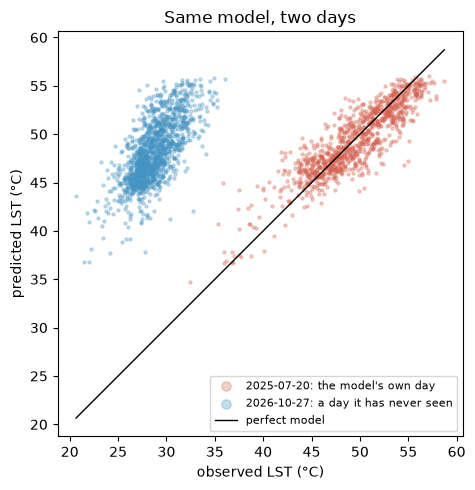

In [24]:
#@title 7.4 · How wrong is the model on a day it has never seen? 🔍
check = fc_to_df(build_training_set(lst_now, dw_now, n=3000, seed=7).classify(rf, "LST_pred").select(["LST", "LST_pred"]))
s_now = scores(check)
print(f"🔍 {SCENE_DATE} (test pixels): mean observed {pred_test['LST'].mean():.1f} °C · "
      f"mean expected {pred_test['LST_pred'].mean():.1f} °C · RMSE {s['RMSE (°C)']} °C")
print(f"🔍 {NEWEST}: mean observed {check['LST'].mean():.1f} °C · "
      f"mean expected {check['LST_pred'].mean():.1f} °C · RMSE {s_now['RMSE (°C)']} °C")
print(f"🔍 On {NEWEST} the model is {(check['LST_pred'] - check['LST']).mean():+.1f} °C off on average. "
      "It sees only land cover, so it still expects the heat of its own day.")

lo = min(check["LST"].min(), pred_test["LST"].min(), pred_test["LST_pred"].min())
hi = max(check["LST"].max(), check["LST_pred"].max(), pred_test["LST"].max())
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(pred_test["LST"], pred_test["LST_pred"], s=5, alpha=0.3, color="#d6604d", label=f"{SCENE_DATE}: the model's own day")
ax.scatter(check["LST"], check["LST_pred"], s=5, alpha=0.3, color="#4393c3", label=f"{NEWEST}: a day it has never seen")
ax.plot([lo, hi], [lo, hi], color="black", lw=1, label="perfect model")
ax.set_xlabel("observed LST (°C)")
ax.set_ylabel("predicted LST (°C)")
ax.set_title("Same model, two days")
ax.set_aspect("equal")
ax.legend(fontsize=8, markerscale=3)
plt.tight_layout()
plt.show()

**Reading the live feed**
- The model learned one hot July day. In autumn the sun is lower and the air is cooler, so every surface is cooler.
- The model does not know the date or the weather. It sees only land cover, so it still expects July heat.
- The blue points still rise from left to right. The model puts the heat in roughly the right places, but at the wrong level.
- A shadow shows this gap as soon as the data arrive. It does not fix it. Fixing it means new data and re-training: that is where the twin begins (§8).

### ✅ What you have built is a digital shadow
- It finds the newest satellite image automatically.
- Function, `shadow_step()` finds newest image, refreshes land cover, applies the model and compares prediction to the observed heat.
- In production a scheduler (for example a daily cron job or a cloud function) would call it at every overpass.
- It showed that a model of one summer day fails in autumn.

Next: use the model to test a decision, and close the loop.

## 8 · Stage 3 · Digital twin: test a decision, then close the loop
> **Learning objectives**
> - Use the model to test a decision before it is made
> - Test how planting trees impacts the temperature.
> - See what closing the loop would take.

A twin does more than mirror the city. It simulates decisions, and people use it to choose. When a decision is carried out, the same data feed observes the effect, and the model learns from it. That is closing the loop.

### Simulate: what if we plant trees?
We raise the probability of trees inside an area, shrink the other classes so that the probabilities still add up to 1, and let the same forest predict the temperature again.

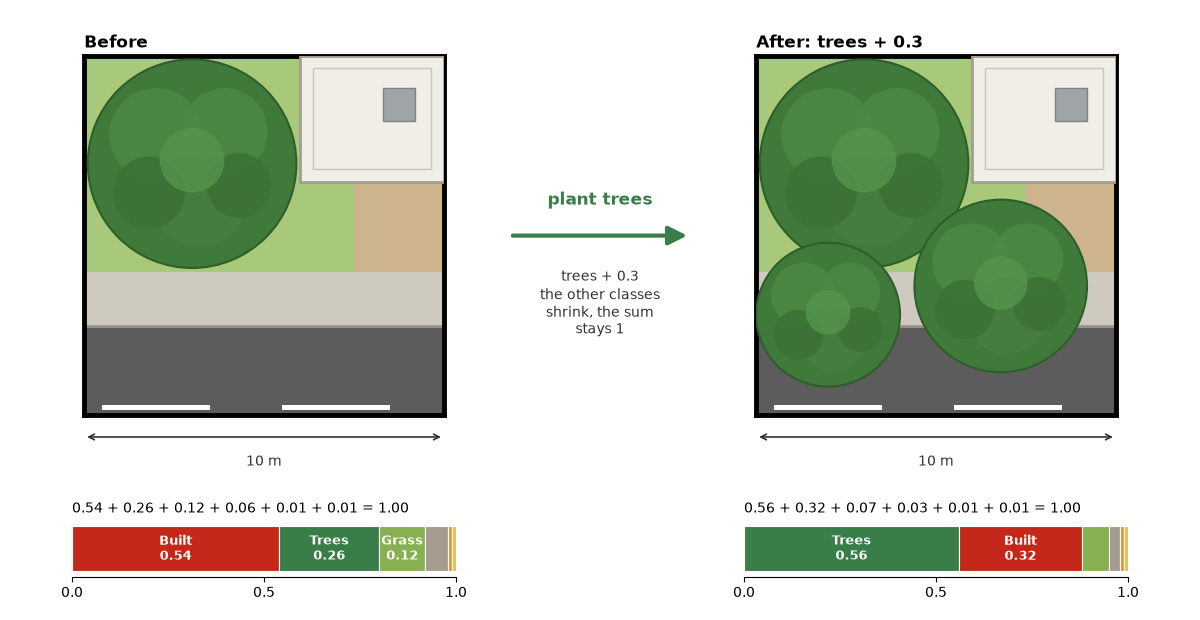

Use the default area, or change `INTERVENTION` in 8.1. Keep it at least a few hectares: the thermal pixel is 100 m wide.

In [25]:
#@title 8.1 · The intervention area
INTERVENTION = ee.Geometry.Rectangle([10.2964, 36.9054, 10.3009, 36.9090])  # ✏️ default: 16 ha of dense housing between Gammarth and La Marsa
TREE_GAIN = 0.3  #@param {type:"slider", min:0.1, max:0.9, step:0.1}

m_draw = new_map(zoom=14, center=[36.910, 10.295])
m_draw.addLayer(label.clip(AOI), {"min": 0, "max": 8, "palette": DW_COLORS}, "Dominant class")
m_draw.addLayer(outline(INTERVENTION, "0000ff", 3), {}, "Intervention area")
add_legend(m_draw, "Dynamic World", DW_NAMES, DW_COLORS)
display(m_draw)

Map(center=[36.91, 10.295], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

In [26]:
#@title 8.2 · Plant the trees and ask the model 🔍
GIVE_WAY = ["grass", "crops", "shrub_and_scrub", "built", "bare"]   # classes that shrink to make room

def plant_trees(dw, area, gain):
    """Inside `area`: raise trees probabilities, the other land classes shrink proportionally (still summing to 1)."""
    trees = dw.select("trees")
    trees_new = trees.add(gain).min(1)
    added = trees_new.subtract(trees)
    others = dw.select(GIVE_WAY)
    total = others.reduce(ee.Reducer.sum())
    keep = total.subtract(added).max(0).divide(total.max(1e-6))
    changed = (dw.addBands(trees_new.rename("trees"), overwrite=True)
                 .addBands(others.multiply(keep).rename(GIVE_WAY), overwrite=True)
                 .select(DW_CLASSES))
    return dw.select(DW_CLASSES).blend(changed.clip(area))

dw_green = plant_trees(dw_model, INTERVENTION, TREE_GAIN)
green_lst = dw_green.select(FEATURES).classify(rf).rename("LST_pred")
delta = green_lst.subtract(model_lst).rename("dLST")

def area_mean(img, band):
    return img.reduceRegion(ee.Reducer.mean(), INTERVENTION, SCALE, crs=CRS).get(band)

result = ee.Dictionary({
    "before": dw_model.select(DW_CLASSES).reduceRegion(ee.Reducer.mean(), INTERVENTION, SCALE, crs=CRS),
    "after": dw_green.reduceRegion(ee.Reducer.mean(), INTERVENTION, SCALE, crs=CRS),
    "lst_before": area_mean(model_lst, "LST_pred"),
    "lst_after": area_mean(green_lst, "LST_pred"),
    "hectares": INTERVENTION.area(maxError=1).divide(1e4),
    "centre": INTERVENTION.centroid(maxError=1).coordinates(),
}).getInfo()

mix = pd.DataFrame({"before": result["before"], "after": result["after"]}).reindex(FEATURES)
mix.index = [DW_NAMES[DW_CLASSES.index(c)] for c in FEATURES]
print("🔍 Land-cover probabilities inside the area, before and after:")
display(mix[(mix["before"] > 0.01) | (mix["after"] > 0.01)].round(2))
change = result["lst_after"] - result["lst_before"]
print(f"🔍 {result['hectares']:.0f} ha · model LST {result['lst_before']:.1f} → {result['lst_after']:.1f} °C "
      f"· change {change:+.1f} °C")

lon, lat = result["centre"]
m = new_map(zoom=15, center=[lat, lon])
m.addLayer(model_lst.updateMask(land), LST_VIS, "Model LST today", False)
m.addLayer(green_lst.updateMask(land), LST_VIS, "Model LST with more trees", False)
m.addLayer(delta.updateMask(delta.abs().gt(0.05)), {"min": -5, "max": 5, "palette": DIVERGING},
           "Change in LST (°C): blue = cooler")
m.addLayer(outline(INTERVENTION, "000000", 2), {}, "Intervention area")
display(m)

🔍 Land-cover probabilities inside the area, before and after:


,before,after
Water,0.03,0.03
Trees,0.03,0.29
Grass,0.04,0.02
Flooded vegetation,0.03,0.03
Crops,0.04,0.03
Shrub & scrub,0.05,0.04
Built,0.62,0.44
Bare,0.10,0.07


🔍 16 ha · model LST 46.0 → 44.8 °C · change -1.2 °C


Map(center=[36.90720000725411, 10.298649999970955], controls=(WidgetControl(options=['position', 'transparent_…

### Close the loop
Suppose the city likes the result of 8.2 and plants the trees. The loop then closes like this:
1. **Decide:** the parks department picks the area and the share of trees, based on 8.2.
2. **Act:** the trees are planted. In the following months Dynamic World sees more trees there.
3. **Observe:** `shadow_step()` keeps running at every overpass and measures the LST of the area.
4. **Learn:** compare the observed cooling with the cooling predicted in 8.2. Re-train the model with the new pixels, so that it learns from the real effect.

This notebook has a tool for every step except *Act*: §6 trains a model, §7 observes, 8.2 predicts. *Act* needs the city, and *Learn* needs the months after it.

| Step of the loop | In this notebook | What it would take |
|---|---|---|
| Observe | ✅ Landsat LST, Dynamic World (§3–5, §7) | weather stations or ERA5-Land air temperature |
| Update state | ✅ `shadow_step()` (§7) | a scheduler and a database |
| Predict & simulate | 🟡 what-if in 8.2, no forecast | time-series forecasting (this afternoon) |
| Decide | ❌ | a rule with a named owner, e.g. "plant where the model predicts at least 1 °C of cooling" |
| Act | ❌ | the parks department plants the trees; on a farm, an irrigation controller |
| Learn | 🟡 training code in §6 | after each action, compare the predicted and the observed effect, then re-train |

```python
# Sketch of a heat-island twin (pseudo-code, not meant to run)
plan = plant_trees(dw_model, INTERVENTION, TREE_GAIN)    # simulate                       (8.2)
predicted = cooling(model, plan)                          # the predicted effect
approve(plan, owner="parks department")                   # decide: a named owner
plant(plan)                                               # act: digital → physical
for scene in new_landsat_overpasses():                    # event-driven ingest
    lst, land_cover, expected, diff = shadow_step(scene)  # observe, update the state      (§7)
    observed = cooling_seen_in(INTERVENTION, lst)         # the effect, seen by the same feed
    log(predicted, observed)                              # was the cooling as predicted?
    model = retrain(model, new_pixels(scene))             # learn                          (§6)
```

**The same loop on a farm.** Replace the city with an irrigated perimeter:

| Loop step | Urban heat island | Irrigation |
|---|---|---|
| Observe | LST at every overpass | LST at every overpass, soil-moisture probes |
| Update state | heat map and land cover | each field's temperature next to a well-watered field of the same crop |
| Predict & simulate | heat-wave outlook, greening scenarios | water-stress outlook, irrigation scenarios |
| Decide | where to plant, when to alert | which field to irrigate, and how much |
| Act | city services | farmer or irrigation controller |
| Learn | did the area cool as predicted? | did the field cool after irrigation? |

**For discussion:** Which decision in your region would such a twin support, and who owns it? Which of your data already arrive automatically? Is a good shadow enough for your case?

## 🎉 Wrap-up
- **Observe:** you turned Landsat's thermal band into land surface temperature and removed the clouds.
- **Digital model (§6):** a Random Forest explains much of the heat pattern of one summer day from land cover alone. You tested it on pixels it had never seen.
- **Digital shadow (§7):** one function, `shadow_step()`, turns the newest overpass into a live comparison of observed and expected heat, with no human choice. It showed that the model of one July day fails in autumn.
- **Digital twin (§8):** the model tested a decision: planting trees. To close the loop, the city must act, the shadow must observe the effect, and the model must learn from it.

### References
- Brown, C. F. et al. (2022). Dynamic World, near real-time global 10 m land use land cover mapping. *Scientific Data* 9, 251. https://doi.org/10.1038/s41597-022-01307-4
- Charfi, Krout & Dahech (2014). Vegetation in the urban area of Tunis: a study of impacts on temperature and light. *Climatologie* 11, 72–78. https://doi.org/10.4267/climatologie.534
- Kritzinger, W. et al. (2018). Digital Twin in manufacturing: a categorical literature review and classification. *IFAC-PapersOnLine* 51(11), 1016–1022.
- Oxoli, D., Vavassori, A. & Brovelli, M. A. (2026). A prototype Earth observation-based framework for simulating urban intervention effects on land surface temperature. Code: https://github.com/gisgeolab/SURE
- USGS. Landsat Collection 2 Level-2 Science Products. https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products

*Prepared by OIKON for the DTT4SD Erasmus+ project.*